# Fundamental Signals and Portfolio Construction in US Equities
 **DSA5205 Project 2 | Team 34**

 We investigate a long-only US equity portfolio using supplied market and accounting data over 2014–2025. The year 2014 provides feature warm-up; WQ directions are calibrated in 2015–2017 and WQ candidates are screened in 2018–2019. Cross-validation uses 2020–2022, strategy selection uses 2023, and testing uses 2024–2025.

 A direct-score baseline averages six signed fundamental ranks. Ridge, Lasso and XGBoost learn the same ten-session return using feature sets selected by CV. Each strategy targets 100 stocks with a rank-150 retention buffer, and rebalances every ten sessions. Validation compares equal, square-root capitalization and capitalization weights under a common 2% formation target cap. Signals formed at the close execute at the next close, with a 10bps charge per dollar bought or sold. SPY and matched-universe allocations are the benchmarks.

 The supplied inputs are daily panels and accounting-event tables. They are not a complete historical vendor-vintage archive.

## 1. Setup

In [1]:
from pathlib import Path
import sys,json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display,Markdown
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src/usq/project2/data_preparation.py').exists())
sys.path.insert(0,str(ROOT/'src'))
# Set this to your trusted snapshot folder, or use TEAM34_DATA_DIR.
DATA_DIRECTORY = None  # Example: '/your/local/path/team17_close10_2014_2025'
from usq.project2.notebook_paths import resolve_data_directory
DATA = resolve_data_directory(ROOT, DATA_DIRECTORY)
print('Input snapshot:', DATA)
from datetime import datetime
WORK=ROOT/'runs'/datetime.now().strftime('experiment_%Y%m%d_%H%M%S_%f')
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'figure.dpi':115,'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.2})
get_ipython().run_line_magic('matplotlib','inline')
assert not WORK.exists(), "A clean run requires a new experiment directory."

Matplotlib is building the font cache; this may take a moment.


Input snapshot: /Users/jiarui/Documents/Codex/2026-11-02/python-data-dta-csho-ceq-ni/outputs/team17_close10_2014_2025


## 2. Input Data, Cleaning and Audit
 Read the supplied panels and event metadata, verify input hashes and require unique, sorted dates and security identifiers. Align all fields to the same axes; missing observations are not silently filled with zero or removed using future survival.

 A bar is materially inconsistent when an open/close lies outside its high–low interval by **more than $0.01001 and more than 0.1% of closing price**. Small floating-point differences are not discarded. Reviewed material anomalies are quarantined across OHLC, adjusted prices, price-derived fields and trading availability. Their security histories remain in the universe. Source files are never edited.

 Zero reported volume is counted separately and retained; execution uses the supplied trading-availability flag rather than claiming a liquidity or capacity model. Accounting negatives remain valid where economically meaningful. Missing signals are handled explicitly during ranking. Financial availability must not precede fiscal period end; mapped release dates and latest financial vintages remain limitations rather than evidence of complete point-in-time data.

In [2]:
# Audit inputs before constructing an independent research dataset.
from usq.project2.data_preparation import prepare_research_data,material_ohlc
source=lambda field:pd.read_pickle(DATA/'panels'/f'{field}.pkl')
bars={name:source(name) for name in ['open','high','low','close']}
mask=material_ohlc(bars['open'],bars['high'],bars['low'],bars['close'])
universe=source('universe')
display(pd.DataFrame({'audit':['Panel sessions','Security-ID union','Material OHLC violations','Violations in supplied universe'],
                      'count':[len(universe),len(universe.columns),int(mask.to_numpy().sum()),int((mask&universe.eq(1)).to_numpy().sum())]}))
quality=[{'field':name,'nonpositive_prices':int(f.le(0).to_numpy().sum())} for name,f in bars.items()]
display(pd.DataFrame(quality))
assert all(row['nonpositive_prices']==0 for row in quality)
volume=source('volume')
display(pd.Series({'negative_volume':int(volume.lt(0).to_numpy().sum()),'zero_volume':int(volume.eq(0).to_numpy().sum())}))
assert not volume.lt(0).any().any()
del volume
database=prepare_research_data(DATA,WORK)
report=json.loads((WORK/'data_complete.json').read_text())
display(pd.DataFrame({k:[v] for k,v in report.items() if k not in ['binding','financial_audit']}))
audit=pd.read_csv(WORK/'input_audit.csv')
display(audit)
display(pd.read_csv(WORK/'financial_availability.csv'))
del bars,mask,universe

,audit,count
0,Panel sessions,3018
1,Security-ID union,4366
2,Material OHLC violations,2
3,Violations in supplied universe,1


,field,nonpositive_prices
0,open,0
1,high,0
2,low,0
3,close,0


negative_volume        0
zero_volume        11276
dtype: int64

{"output": "/Users/jiarui/Documents/Codex/2026-11-02/python-data-dta-csho-ceq-ni/work/team34_main_validation_20261111/runs/experiment_20261111_110038_076238/database", "stock_fields": 47, "passed": true, "research_accepted": false, "shape": [3018, 4366], "label_coverage_on_supplied_2015_2025_universe": 0.993603920585218, "label_missing_pct_on_supplied_2015_2025_universe": 0.6396079414782041, "last_signal_date_with_calendar_matured_target": "20251215", "last_eleven_rows_all_missing": true, "aliases_identical": true, "label_version": "next_close_10d_v2", "source_snapshot_unchanged": true, "vwap_used_for_label": false, "legacy_backtest_engine_migrated": true, "warning": "Ordinary workflow/backtest/Barra paths use close_adj with next-close execution. Terminal events and missing held industry still require explicit source resolution; no formal full-period strategy has been validated."}


,passed,source_files_verified,calendar_sessions,SID_union,quarantined_bars,quarantined_eligible_bars,last_11_targets_censored
0,True,75,3018,4366,2,1,True


,field,rows,securities,missing_cells,infinite_cells,eligible_coverage
0,adj_factor,3018,4366,4181297,0,1.000000
1,adjustment_segment,3018,4366,0,0,1.000000
2,book_equity,3018,4366,3586576,0,0.999379
3,close,3018,4366,4181297,0,1.000000
4,close_adj,3018,4366,4181297,0,1.000000
5,crsp_shares_out,3018,4366,4181297,0,1.000000
6,daily_return,3018,4366,4181596,0,0.999998
7,delisting_event,3018,4366,0,0,1.000000
8,earnings_ttm,3018,4366,3732516,0,0.998884
9,high_adj,3018,4366,4181451,0,1.000000


,field,availability_basis,events
0,book_equity,fdateq_next_session_fallback_not_announcement,49
1,book_equity,rdq_next_session,184818
2,capital_expenditures_q,fdateq_next_session_fallback_not_announcement,41
3,capital_expenditures_q,rdq_next_session,181725
4,capital_expenditures_ttm,fdateq_next_session_fallback_not_announcement,39
5,capital_expenditures_ttm,rdq_next_session,167909
6,cash,fdateq_next_session_fallback_not_announcement,49
7,cash,rdq_next_session,184877
8,earnings_q,fdateq_next_session_fallback_not_announcement,51
9,earnings_q,rdq_next_session,184663


## 3. Corporate Actions, Coverage and Labels
 Adjusted price identities are checked against the supplied adjustment factors. Return and rolling-feature calculations respect known security adjustment segments. Missing held quotes use explicit stale-mark accounting; valid terminal source returns take priority, and unresolved terminal payoffs remain an assumption.

 The target is $y_{i,T}=P^*_{i,T+11}/P^*_{i,T+1}-1$: ten close-to-close intervals after next-close entry. Entry/exit prices must be observed, positive, and in a valid common segment. Target prices are not forward filled. The last eleven signal dates are censored. Labels are rebuilt after quarantine, not inherited from supplied derived fields.

adjusted_price_relative_error_median    0.000000e+00
adjusted_price_relative_error_max       1.192093e-07
dtype: float64

target_formula                close[T+11]/close[T+1]-1
tail_signal_dates_censored                          11
last_mature_signal                            20251215
eligible_target_coverage                      0.993604
dtype: object

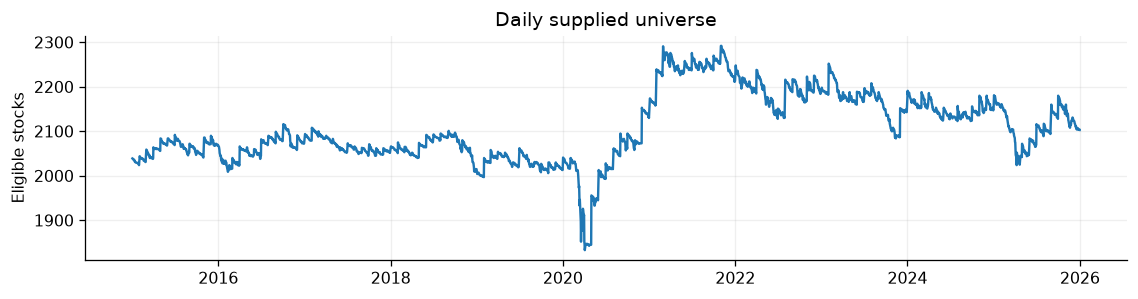

In [3]:
# Check adjustment consistency and exact target maturity.
panel=lambda field:pd.read_pickle(database/'panels'/f'{field}.pkl')
u=panel('universe');cp=panel('close_adj');raw=panel('close');factor=panel('adj_factor')
valid=np.isfinite(cp)&np.isfinite(raw)&np.isfinite(factor)&raw.gt(0)&factor.gt(0)
error=(cp-raw*factor).abs().div(cp.abs()).where(valid)
display(pd.Series({'adjusted_price_relative_error_median':float(error.stack().median()),'adjusted_price_relative_error_max':float(error.max().max())}))
from usq.project2.protocol import validate_target
ends=validate_target(database,u);target=panel('ylabel')
np.testing.assert_array_equal(target.tail(11).isna(),True)
direct=cp.shift(-11)/cp.shift(-1)-1
finite=target.notna()
np.testing.assert_allclose(target.where(finite).to_numpy(),direct.where(finite).to_numpy(),rtol=2e-6,atol=2e-6,equal_nan=True)
display(pd.Series({'target_formula':'close[T+11]/close[T+1]-1','tail_signal_dates_censored':11,'last_mature_signal':str(ends.dropna().index[-1]),'eligible_target_coverage':float((finite&u.eq(1)).to_numpy().sum()/u.eq(1).to_numpy().sum())}))
counts=u.loc['20150101':].eq(1).sum(axis=1)
fig,ax=plt.subplots(figsize=(10,2.7));ax.plot(pd.to_datetime(counts.index),counts);ax.set(ylabel='Eligible stocks',title='Daily supplied universe');fig.tight_layout();plt.show()
del cp,raw,factor,error,direct,valid,finite,target

## 4. Signal Research

### WQ Candidate Screening
Reproduce all 36 available WQ candidates. Determine orientation on 2015–2017, require 2018–2019 signed mean RankIC ≥ 0.01, coverage ≥ 50% and positive mean RankIC in both years, then remove candidates with average absolute daily rank correlation ≥ 0.8. All labels must mature within the relevant period. The target is at most ten signals; no minimum count is forced.


In [4]:
# Rebuild the complete candidate screen from this run's cleaned inputs.
from usq.project2.factor_selection import screen_wq
wq_table,wq_selection=screen_wq(database,WORK/'factor_screen')
display(wq_table.sort_values('stability_rankic_signed',ascending=False))
wq_annual=pd.read_csv(WORK/'factor_screen'/'WQ_annual.csv')
passed=wq_table.loc[wq_table.passes_predeclared_rules,'factor']
display(wq_annual.loc[wq_annual.factor.isin(passed)].pivot(index='factor',columns='year',values='signed_rankic'))
display(pd.DataFrame(wq_selection['decisions']))
print("Selected WQ factors:",wq_selection['wq'])


{"stage": "WQ_screen", "factor": "WQ002", "passed": false}


{"stage": "WQ_screen", "factor": "WQ003", "passed": false}


{"stage": "WQ_screen", "factor": "WQ004", "passed": true}


{"stage": "WQ_screen", "factor": "WQ006", "passed": false}


{"stage": "WQ_screen", "factor": "WQ008", "passed": false}


{"stage": "WQ_screen", "factor": "WQ009", "passed": false}


... (30 outputs left out)

,factor,direction,early_rankic,stability_rankic_signed,stability_coverage,positive_stability_years,passes_predeclared_rules
2,WQ004,1,0.013204,0.017049,0.991777,2,True
31,WQ052,1,0.013684,0.014278,0.882555,2,True
13,WQ019,1,0.018612,0.011891,0.879537,2,True
22,WQ035,1,0.007174,0.010630,0.972920,2,True
24,WQ038,1,0.005470,0.010612,0.990837,2,True
18,WQ026,1,0.006840,0.010313,0.897911,2,True
20,WQ033,1,0.000954,0.008360,0.999982,2,False
35,WQ101,-1,-0.001093,0.008123,0.999982,2,False
33,WQ054,1,0.002380,0.007654,0.999963,2,False
11,WQ016,1,0.003118,0.007490,0.995655,2,False


year,2018,2019
factor,,
WQ004,0.028026,0.005616
WQ019,0.003709,0.020412
WQ026,0.011382,0.009199
WQ035,0.014664,0.006429
WQ038,0.014337,0.006732
WQ052,0.014748,0.013787


,factor,accepted,max_abs_daily_rank_corr,correlations
0,WQ004,True,0.000000,{}
1,WQ052,True,0.413863,{'WQ004': 0.4138630484836967}
2,WQ019,True,0.535966,"{'WQ004': 0.4502798838638302, 'WQ052': 0.53596..."
3,WQ035,True,0.465040,"{'WQ004': 0.46503997027470645, 'WQ052': 0.3053..."
4,WQ038,True,0.720440,"{'WQ004': 0.5441595331556084, 'WQ052': 0.30228..."
5,WQ026,True,0.152323,"{'WQ004': 0.12567376660477664, 'WQ052': 0.1523..."


Selected WQ factors: ['WQ004', 'WQ052', 'WQ019', 'WQ035', 'WQ038', 'WQ026']


### Fundamental Signal Construction and Development Evidence
 For the first four signals, estimate daily cross-sectional OLS with an intercept on at least 30 finite eligible pairs:
 $$g(A_{i,T})=a_T+b_Tg(B_{i,T})+\varepsilon_{i,T},\qquad g(x)=\operatorname{sign}(x)\log(1+|x|/10^6).$$
 F1 uses TTM net income against capitalization; F2 uses book equity against capitalization; F3 uses quarterly sales against capitalization; F4 uses quarterly net income against book equity. F5 is free cash flow divided by capitalization plus liabilities less cash. F6 compares earnings with a seasonal historical expectation, normalized by capitalization strictly before release.

 Fundamental factor directions use 2015–2018 RankIC and are frozen thereafter. F2 and F3 have negative directions; stronger positive residuals are not universally preferred. Each development or validation statistic uses only targets matured by that phase's end. The composite has no fitted return-prediction coefficients.

{"stage": "final_factor_rebuilt", "factor": "F01_EP_reconstructed"}


{"stage": "final_factor_rebuilt", "factor": "F02_BP_reconstructed"}


{"stage": "final_factor_rebuilt", "factor": "F03_SPQ_reconstructed"}


{"stage": "final_factor_rebuilt", "factor": "F04_ROEQ_reconstructed"}


{"stage": "final_factor_rebuilt", "factor": "F05_FCF_yield"}


{"stage": "final_factor_rebuilt", "factor": "F06_earnings_surprise"}


,factor,phase,direction,rankic,ic,coverage,defined_days
0,F01_EP_reconstructed,direction,1,0.001808,-0.003645,0.999812,995
1,F01_EP_reconstructed,development,1,0.016569,0.009248,0.998131,745
2,F01_EP_reconstructed,validation,1,0.011408,-0.015629,0.997652,239
4,F02_BP_reconstructed,direction,-1,0.004283,0.003397,0.999900,995
5,F02_BP_reconstructed,development,-1,-0.017080,0.002620,0.999055,745
6,F02_BP_reconstructed,validation,-1,-0.006954,-0.001969,0.998242,239
8,F03_SPQ_reconstructed,direction,-1,0.004146,0.000342,0.999980,995
9,F03_SPQ_reconstructed,development,-1,-0.030854,-0.030307,0.999316,745
10,F03_SPQ_reconstructed,validation,-1,-0.026496,-0.019334,0.998704,239
12,F04_ROEQ_reconstructed,direction,1,0.015075,0.001599,0.999893,995


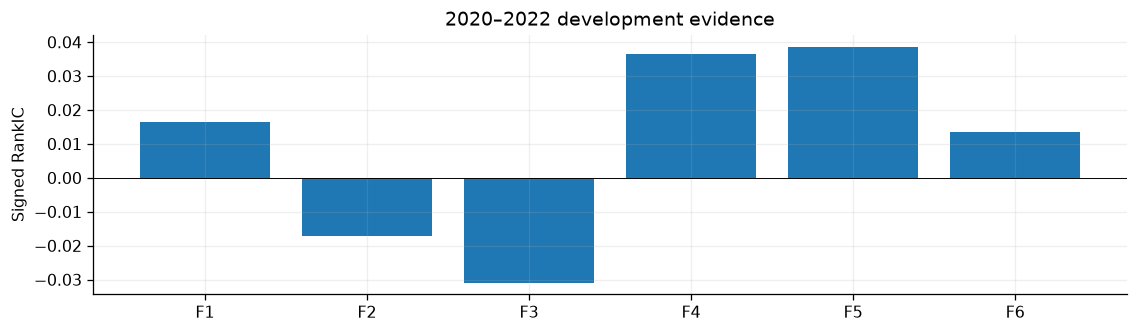

In [5]:
# Construct factors using contemporaneously available information.
from usq.project2.strategy_study import StrategyStudy,create_experiment_config
config=create_experiment_config(database,WORK,wq_selection)
study=StrategyStudy(config,WORK/'portfolios',standalone=True)
stats=pd.read_csv(study.out/'factor_statistics.csv')
display(stats.query("phase in ['direction','development','validation']"))
development=stats.query("phase=='development'").set_index('factor')
fig,ax=plt.subplots(figsize=(10,3));ax.bar(range(6),development.rankic);ax.set_xticks(range(6),['F1','F2','F3','F4','F5','F6']);ax.axhline(0,color='black',lw=.6);ax.set(ylabel='Signed RankIC',title='2020–2022 development evidence');fig.tight_layout();plt.show()

## 5. Supervised Models and Expanding-Time Cross-Validation
All three estimators share the same eligible universe, raw ten-session target and execution rule. Every feature family includes six fundamental ranks and their missing indicators. Missing rank values are zero; missing flags are retained. No target clipping or post-hoc transformation is applied.

Ridge penalizes squared coefficients; Lasso penalizes absolute coefficients and may eliminate signals; XGBoost fits a regularized ensemble of shallow trees. Complexity is not assumed to improve economic performance.

**Cross-validation:** three annual folds (2020, 2021 and 2022), each with fresh H1 and H2 fits using cumulative history from 2015. A training label must end strictly before its forecast half starts. CV scoring excludes targets ending beyond the fold year. There is no random K-fold split.

The small grids are Ridge per-sample penalty {0.1, 0.01, 0.001}, Lasso penalty {0.0005, 0.0001, 0.00001}, and XGBoost depth {2,3}. XGBoost fixes 120 trees, learning rate 0.05 and seed 5205. Maximize equal-fold mean daily RankIC with at least 80% defined days in every fold; ties prefer greater shrinkage or shallower depth. All predictions are generated by actual fits. Every run starts from a new experiment directory and fits all models again; prior-run caches are not reused.

Three feature families are compared: six fundamental factors (12 columns including missing flags), fundamentals plus the WQ signals passing the screen, and an engineered family. Engineering adds 20-session changes in fundamental ranks, 5/20/60-session momentum, 20-session volatility and volume surprise, and log capitalization. Transformations use only information available at each signal close. Feature families and hyperparameters are jointly compared on three expanding annual CV folds (2020–2022). Ridge searches four penalties, Lasso five penalties, and XGBoost twelve depth/learning-rate/L2 combinations per family, for 63 configurations and 378 CV fits. XGBoost uses 200 trees. Selection uses equal-fold mean RankIC, with per-fold validity checks; worst-fold scores and fold dispersion are also reported. The 2023 validation period chooses the strategy family.


### Overfitting controls

| Control | Implementation and evidence |
|---|---|
| Limit model complexity | Ridge tunes four L2 penalties. Lasso tunes five L1 penalties. XGBoost uses 200 trees, depths 2–4, two learning rates and two L2 penalties, with 80% row subsampling and minimum child weight 100. |
| Keep selection chronological | WQ direction and screening end before CV. The three forward CV folds compare a predefined grid and require finite RankIC on at least 80% of eligible days per fold. Inspect the average and worst-fold scores below. |
| Enforce label timing | Every training label ends before its forecast half starts. Each CV fold scores only labels maturing by year-end. The training history records the realized bounds. |
| Freeze decisions before testing | CV fixes feature families and hyperparameters. The 2023 ledger selects the strategy family by net Sharpe with a cash constraint. The 2024–2025 test uses those choices with scheduled refits. |


{"stage": "fit_complete", "model": "ridge", "half": "2020H1", "params": "{\"alpha_per_sample\": 1.0, \"feature_set\": \"fundamental\"}", "samples": 2521845, "training_target_mean": 0.0046092278957963724, "features": 12, "feature_set": "fundamental", "fit_converged": true, "solver_iterations": null, "solver_dual_gap": null, "warnings": [], "train_first": "20150114", "train_last_signal": "20191213", "train_last_label_end": "20191231", "forecast_start": "20200101", "forecast_end": "20200630", "seconds": 0.6742422580718994, "nonzero_value_coefficients": 6, "nonzero_missing_coefficients": 6}


{"stage": "fit_complete", "model": "ridge", "half": "2020H2", "params": "{\"alpha_per_sample\": 1.0, \"feature_set\": \"fundamental\"}", "samples": 2763371, "training_target_mean": 0.0036812038309275044, "features": 12, "feature_set": "fundamental", "fit_converged": true, "solver_iterations": null, "solver_dual_gap": null, "warnings": [], "train_first": "20150114", "train_last_signal": "20200615", "train_last_label_end": "20200630", "forecast_start": "20200701", "forecast_end": "20201231", "seconds": 0.5565781593322754, "nonzero_value_coefficients": 6, "nonzero_missing_coefficients": 6}


{"stage": "CV_fold", "model": "ridge", "candidate": 0, "year": 2020, "params": "{\"alpha_per_sample\": 1.0, \"feature_set\": \"fundamental\"}", "feature_set": "fundamental", "fit_converged": true, "rankic": 0.04323589982400787, "ic": 0.04586393408264771, "defined_fraction": 1.0, "scored_days": 242}


{"stage": "fit_complete", "model": "ridge", "half": "2021H1", "params": "{\"alpha_per_sample\": 1.0, \"feature_set\": \"fundamental\"}", "samples": 3023300, "training_target_mean": 0.005553225337035873, "features": 12, "feature_set": "fundamental", "fit_converged": true, "solver_iterations": null, "solver_dual_gap": null, "warnings": [], "train_first": "20150114", "train_last_signal": "20201215", "train_last_label_end": "20201231", "forecast_start": "20210101", "forecast_end": "20210630", "seconds": 0.8542051315307617, "nonzero_value_coefficients": 6, "nonzero_missing_coefficients": 6}


{"stage": "fit_complete", "model": "ridge", "half": "2021H2", "params": "{\"alpha_per_sample\": 1.0, \"feature_set\": \"fundamental\"}", "samples": 3294934, "training_target_mean": 0.006471977767192246, "features": 12, "feature_set": "fundamental", "fit_converged": true, "solver_iterations": null, "solver_dual_gap": null, "warnings": [], "train_first": "20150114", "train_last_signal": "20210615", "train_last_label_end": "20210630", "forecast_start": "20210701", "forecast_end": "20211231", "seconds": 0.7626872062683105, "nonzero_value_coefficients": 6, "nonzero_missing_coefficients": 6}


{"stage": "CV_fold", "model": "ridge", "candidate": 0, "year": 2021, "params": "{\"alpha_per_sample\": 1.0, \"feature_set\": \"fundamental\"}", "feature_set": "fundamental", "fit_converged": true, "rankic": -0.06823305726511827, "ic": -0.053581725453879014, "defined_fraction": 1.0, "scored_days": 241}


... (561 outputs left out)

,model,candidate,params,feature_set,fit_converged,year,rankic,ic,defined_fraction,scored_days
0,ridge,0,"{""alpha_per_sample"": 1.0, ""feature_set"": ""fund...",fundamental,True,2020,0.043236,0.045864,1.0,242
1,ridge,0,"{""alpha_per_sample"": 1.0, ""feature_set"": ""fund...",fundamental,True,2021,-0.068233,-0.053582,1.0,241
2,ridge,0,"{""alpha_per_sample"": 1.0, ""feature_set"": ""fund...",fundamental,True,2022,0.038525,0.029687,1.0,240
3,ridge,1,"{""alpha_per_sample"": 0.1, ""feature_set"": ""fund...",fundamental,True,2020,0.033009,0.034734,1.0,242
4,ridge,1,"{""alpha_per_sample"": 0.1, ""feature_set"": ""fund...",fundamental,True,2021,-0.063250,-0.048883,1.0,241
...,...,...,...,...,...,...,...,...,...,...
184,xgboost,34,"{""max_depth"": 4, ""learning_rate"": 0.08, ""reg_l...",engineered,True,2021,-0.011795,-0.011752,1.0,241
185,xgboost,34,"{""max_depth"": 4, ""learning_rate"": 0.08, ""reg_l...",engineered,True,2022,0.021901,0.015777,1.0,240
186,xgboost,35,"{""max_depth"": 4, ""learning_rate"": 0.08, ""reg_l...",engineered,True,2020,-0.003070,0.001114,1.0,242
187,xgboost,35,"{""max_depth"": 4, ""learning_rate"": 0.08, ""reg_l...",engineered,True,2021,-0.010672,-0.010171,1.0,241


,candidate,params,CV_mean_rankic
ridge,4,"{'alpha_per_sample': 1.0, 'feature_set': 'comb...",0.016264
lasso,6,"{'alpha': 0.0005, 'feature_set': 'combined'}",0.023023
xgboost,22,"{'max_depth': 4, 'learning_rate': 0.08, 'reg_l...",0.010167


,model,candidate,feature_set,mean_rankic,worst_fold_rankic,fold_dispersion,minimum_defined_fraction,finite_folds,fit_converged,eligible
0,lasso,0,fundamental,NaN,NaN,NaN,0.0,0,True,False
1,lasso,1,fundamental,NaN,NaN,NaN,0.0,0,True,False
2,lasso,2,fundamental,0.007576,-0.054019,0.053528,1.0,3,True,True
3,lasso,3,fundamental,0.002486,-0.048600,0.044411,1.0,3,True,True
4,lasso,4,fundamental,0.002379,-0.045745,0.041877,1.0,3,True,True
...,...,...,...,...,...,...,...,...,...,...
58,xgboost,31,engineered,0.001926,-0.016729,0.019680,1.0,3,True,True
59,xgboost,32,engineered,0.001998,-0.017855,0.020896,1.0,3,True,True
60,xgboost,33,engineered,0.002346,-0.018472,0.021585,1.0,3,True,True
61,xgboost,34,engineered,0.003386,-0.011795,0.017094,1.0,3,True,True


,name,block,transformation
0,WQ004,combined,eligible daily percentile minus .5; neutral ze...
1,WQ052,combined,eligible daily percentile minus .5; neutral ze...
2,WQ019,combined,eligible daily percentile minus .5; neutral ze...
3,WQ035,combined,eligible daily percentile minus .5; neutral ze...
4,WQ038,combined,eligible daily percentile minus .5; neutral ze...
5,WQ026,combined,eligible daily percentile minus .5; neutral ze...
6,F01_EP_reconstructed,fundamental,eligible daily percentile minus .5; neutral ze...
7,change20_F01_EP_reconstructed,engineered,eligible daily percentile minus .5; neutral ze...
8,F02_BP_reconstructed,fundamental,eligible daily percentile minus .5; neutral ze...
9,change20_F02_BP_reconstructed,engineered,eligible daily percentile minus .5; neutral ze...


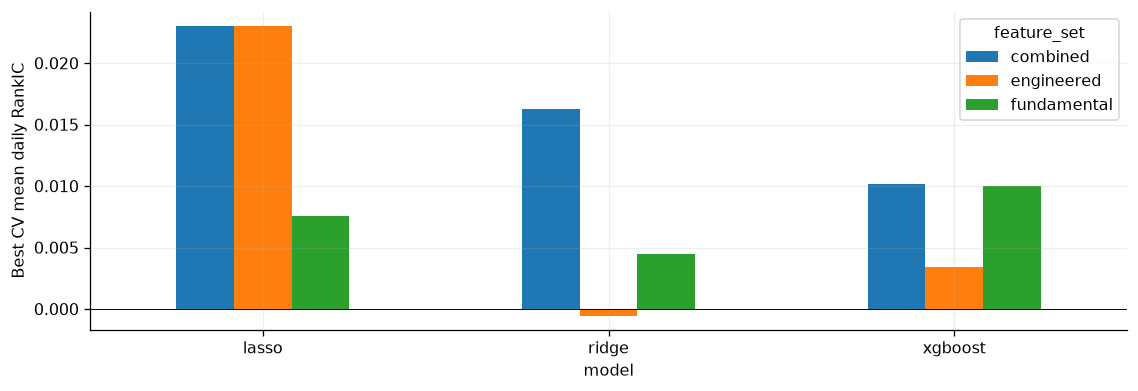

,model,tag,half,samples,train_last_signal,train_last_label_end,forecast_start,reused_verified_fit
0,ridge,cv_grid0,2020H1,2521845,20191213,20191231,20200101,False
1,ridge,cv_grid0,2020H2,2763371,20200615,20200630,20200701,False
2,ridge,cv_grid0,2021H1,3023300,20201215,20201231,20210101,False
3,ridge,cv_grid0,2021H2,3294934,20210615,20210630,20210701,False
4,ridge,cv_grid0,2022H1,3579334,20211215,20211231,20220101,False
...,...,...,...,...,...,...,...,...
373,xgboost,cv_grid35,2020H2,2763371,20200615,20200630,20200701,False
374,xgboost,cv_grid35,2021H1,3023300,20201215,20201231,20210101,False
375,xgboost,cv_grid35,2021H2,3294934,20210615,20210630,20210701,False
376,xgboost,cv_grid35,2022H1,3579334,20211215,20211231,20220101,False


In [6]:
# Tune only on expanding historical folds; purge unfinished labels.
from usq.project2.model_selection import ReturnModelExperiment
learners=ReturnModelExperiment(study,refit=True)
cv,parameters=learners.cross_validate()
display(cv)
display(pd.DataFrame(parameters).T)
view=pd.read_csv(learners.out/'CV_comparison.csv')
display(view)
display(pd.read_csv(learners.out/'feature_manifest.csv'))
# Compare the best eligible configuration within each feature family.
best=view.query('eligible').groupby(['model','feature_set']).mean_rankic.max().unstack()
fig,ax=plt.subplots(figsize=(10,3.5));best.plot.bar(ax=ax);ax.axhline(0,color='black',lw=.6);ax.set_ylabel('Best CV mean daily RankIC');ax.tick_params(axis='x',rotation=0);fig.tight_layout();plt.show()
history=pd.read_csv(learners.out/'training_history.csv')
assert (history.train_last_label_end.astype(str)<history.forecast_start.astype(str)).all()
display(history[['model','tag','half','samples','train_last_signal','train_last_label_end','forecast_start','reused_verified_fit']])

## 6. Portfolio Rule and Chronological Validation
 Center each signed contemporaneous percentile rank and average all six components:
 $$S_{i,T}=\frac{1}{6}\sum_{k=1}^6\left[\operatorname{rank}_T(d_kf_{i,k,T})-0.5\right].$$
 A missing component contributes zero, with the denominator fixed at six. Eligibility uses the supplied universe, positive finite capitalization and observable pre-specified backward-looking price features. The latter are a coverage condition, not inputs to the fundamental score.

 Incumbents still within rank 150 are retained, then remaining slots are filled to Top100. Ties use a stable seed-5205 security hash. All candidate weights are water-filled to the 2% formation cap; actual holdings may drift. Unfillable buys remain cash and unsellable holdings remain held. Replacements do not use future execution quotes.

 Each score source—six-factor direct score, Ridge, Lasso and XGBoost—is paired with equal, square-root capitalization and capitalization weights. After CV fixes prediction specifications, the 2023 validation ledger selects the score-and-weight pair with the highest net Sharpe among candidates with finite Sharpe and mean cash no greater than 5%. Ties prefer lower turnover, then case name. Full eligible pool portfolios are benchmarks. The best eligible weighting within each score source is also frozen for the period comparison.


In [7]:
# Freeze the score and weighting using validation performance.
from usq.project2.model_selection import PORTFOLIO_CANDIDATES

study.replay_phase('validation')
learners.forecast('validation')
selection = json.loads((learners.out / 'frozen_family.json').read_text())
display(selection)

model_names = {'fundamental': 'Six-factor direct score', 'ridge': 'Ridge',
               'lasso': 'Lasso', 'xgboost': 'XGBoost'}
weight_names = {'equal': 'Equal', 'sqrt_cap': 'Square-root cap', 'cap': 'Market cap'}
case_labels = {case: (model_names[model], weight_names[weight])
               for model, cases in PORTFOLIO_CANDIDATES.items() for weight, case in cases.items()}
frozen_cases = {model: case for model, case in selection['selected_by_model'].items() if case}


def show_portfolio_tables(phase_rows, *, validation=False):
    rows = phase_rows.set_index('case')
    metrics = {'annual_return': 'Net CAGR', 'annual_volatility': 'Annual volatility',
               'sharpe': 'Net Sharpe', 'max_drawdown': 'Max drawdown',
               'mean_daily_turnover': 'Mean daily turnover', 'mean_cash': 'Mean cash'}
    table = rows.loc[list(case_labels), list(metrics)].copy()
    if validation:
        table['Validation status'] = np.where(
            table.index == selection['selected_case'], 'Selected',
            np.where(np.isfinite(table.sharpe) & table.mean_cash.le(.05), 'Eligible', 'Ineligible'),
        )
    table.index = pd.MultiIndex.from_tuples(
        [case_labels[case] for case in table.index], names=['Score', 'Weighting'])
    for col in metrics:
        table[col] = table[col].map(
            lambda value: '—' if pd.isna(value) else f'{value:.4f}' if col == 'sharpe' else f'{value:.2%}'
        )
    display(Markdown('**Stock-selection candidates**'))
    display(table.rename(columns=metrics))

    comparison = {}
    for title, prefix in [('Six-factor selection', 'fundamental'), ('Full eligible pool', 'pool')]:
        values = rows.loc[[f'{prefix}_{weight}' for weight in weight_names],
                          ['annual_return', 'sharpe']].copy()
        values.index = pd.Index(weight_names.values(), name='Weighting')
        values['annual_return'] = values.annual_return.map(lambda value: f'{value:.2%}')
        values['sharpe'] = values.sharpe.map(lambda value: f'{value:.4f}')
        comparison[title] = values.rename(columns=metrics)
    display(Markdown('**Six-factor selection vs. matched full pool**'))
    display(pd.concat(comparison, axis=1))

validation = pd.read_csv(study.out / 'portfolio_summary.csv').query("phase == 'validation'")
show_portfolio_tables(validation, validation=True)


{"stage": "final_portfolio", "case": "pool_equal", "phase": "validation", "CAGR": 0.16699659003456158}


{"stage": "final_portfolio", "case": "fundamental_equal", "phase": "validation", "CAGR": 0.1596799344218769}


{"stage": "final_portfolio", "case": "pool_sqrt_cap", "phase": "validation", "CAGR": 0.18599669029583765}


{"stage": "final_portfolio", "case": "fundamental_sqrt_cap", "phase": "validation", "CAGR": 0.19622710573451174}


{"stage": "final_portfolio", "case": "pool_cap", "phase": "validation", "CAGR": 0.2575925139970259}


{"stage": "final_portfolio", "case": "fundamental_cap", "phase": "validation", "CAGR": 0.19612252596349267}


... (16 outputs left out)

**Stock-selection candidates**

Net CAGR Annual volatility Net Sharpe  \
Score                   Weighting                                               
Six-factor direct score Equal             15.97%            15.69%     1.0223   
                        Square-root cap   19.62%            14.23%     1.3308   
                        Market cap        19.61%            14.20%     1.3325   
Ridge                   Equal             17.36%            18.87%     0.9422   
                        Square-root cap   16.58%            16.59%     1.0074   
                        Market cap        16.35%            16.45%     1.0027   
Lasso                   Equal              0.00%             0.00%          —   
                        Square-root cap    0.00%             0.00%          —   
                        Market cap         0.00%             0.00%          —   
XGBoost                 Equal             25.04%            22.22%     1.1167   
                        Square-root cap   21.47%            19.99%     1.0732   
                        Market cap        22.13%            19.76%     1.1106   

                                        Max drawdown Mean daily turnover  \
Score                   Weighting                                          
Six-factor direct score Equal                -12.85%               1.17%   
                        Square-root cap      -11.30%               0.99%   
                        Market cap           -11.69%               1.00%   
Ridge                   Equal                -13.43%               6.48%   
                        Square-root cap      -11.15%               7.16%   
                        Market cap           -11.20%               7.39%   
Lasso                   Equal                  0.00%               0.00%   
                        Square-root cap        0.00%               0.00%   
                        Market cap             0.00%               0.00%   
XGBoost                 Equal                -20.25%               6.42%   
                        Square-root cap      -19.54%               7.08%   
                        Market cap           -19.77%               7.33%   

                                        Mean cash Validation status  
Score                   Weighting                                    
Six-factor direct score Equal               0.85%          Eligible  
                        Square-root cap     0.88%          Eligible  
                        Market cap          0.88%          Selected  
Ridge                   Equal               0.87%          Eligible  
                        Square-root cap     0.83%          Eligible  
                        Market cap          0.82%          Eligible  
Lasso                   Equal             100.00%        Ineligible  
                        Square-root cap   100.00%        Ineligible  
                        Market cap        100.00%        Ineligible  
XGBoost                 Equal               0.98%          Eligible  
                        Square-root cap     0.90%          Eligible  
                        Market cap          0.87%          Eligible

**Six-factor selection vs. matched full pool**

Six-factor selection            Full eligible pool           
                            Net CAGR Net Sharpe           Net CAGR Net Sharpe
Weighting                                                                    
Equal                         15.97%     1.0223             16.70%     0.9174
Square-root cap               19.62%     1.3308             18.60%     1.1700
Market cap                    19.61%     1.3325             25.76%     1.7583

## 7. Chronological Evaluation and Trading Costs
 A signal formed after T closes trades at the T+1 close; the new holding first earns a return on T+2. The ten-session target is not a mandatory holding duration. Turnover, fees and cash are booked in a self-financing, unlevered ledger.

 Each traded dollar costs 10bps on purchases and sales. Returns include entry and exit fees. Cash earns zero. The reported turnover is half absolute traded notional divided by pretrade wealth. Pool benchmarks hold the same eligible opportunity set every ten sessions without a per-name cap. SPY uses the same investment window.
Validation and testing use a fixed five-calendar-year training window. At each January or July forecast boundary, refit on signals within the preceding five years whose T+11 labels have already matured, then score each trading day in that half. CV fixes features and hyperparameters, and the 2023 ledger fixes the strategy family.

Prediction OOS R² compares squared errors on matched eligible stock-days with a constant forecast equal to the mean target from each fit's training sample. Only targets matured by the end of the scored phase enter the comparison. Portfolio performance uses realized daily P&L after costs, including dates with no matured prediction label.

For the six-factor score, fit an intercept and slope by pooled OLS on eligible stock-days in the five calendar years preceding each forecast half. Keep only training targets that mature strictly before that half starts. Freeze both coefficients for the half and map the existing rank score into ten-session return units. This calibration is used only for prediction diagnostics.

All four forecasts use the same OOS R² formula, 1 − SSE(model) / SSE(training mean). The benchmark is the mean target from that half's training sample, and both errors are measured on the same eligible stock-days with matured labels. The combined 2024–2025 result pools squared errors across both years.

Each period's maximum drawdown is the lowest value of net wealth divided by its running peak minus one. Wealth starts at one at the beginning of the period. The combined 2024–2025 drawdown uses the continuous two-year path.


{"stage": "final_portfolio", "case": "pool_equal", "phase": "evaluation", "CAGR": 0.11651258685440657}


{"stage": "final_portfolio", "case": "fundamental_equal", "phase": "evaluation", "CAGR": 0.24718648426778533}


{"stage": "final_portfolio", "case": "pool_sqrt_cap", "phase": "evaluation", "CAGR": 0.1499438064114469}


{"stage": "final_portfolio", "case": "fundamental_sqrt_cap", "phase": "evaluation", "CAGR": 0.2579584786547764}


{"stage": "final_portfolio", "case": "pool_cap", "phase": "evaluation", "CAGR": 0.21200751718939337}


{"stage": "final_portfolio", "case": "fundamental_cap", "phase": "evaluation", "CAGR": 0.249181633943254}


... (22 outputs left out)

**Stock-selection candidates**

Net CAGR Annual volatility Net Sharpe  \
Score                   Weighting                                               
Six-factor direct score Equal             24.72%            18.67%     1.2764   
                        Square-root cap   25.80%            17.02%     1.4336   
                        Market cap        24.92%            16.81%     1.4074   
Ridge                   Equal              9.55%            22.23%     0.5210   
                        Square-root cap   12.46%            20.81%     0.6680   
                        Market cap        13.45%            20.74%     0.7120   
Lasso                   Equal              9.72%            23.28%     0.5144   
                        Square-root cap   11.29%            19.16%     0.6538   
                        Market cap        11.29%            18.66%     0.6660   
XGBoost                 Equal             13.66%            26.29%     0.6180   
                        Square-root cap   12.33%            25.11%     0.5881   
                        Market cap        12.61%            24.91%     0.6007   

                                        Max drawdown Mean daily turnover  \
Score                   Weighting                                          
Six-factor direct score Equal                -20.87%               1.08%   
                        Square-root cap      -20.78%               0.92%   
                        Market cap           -20.76%               0.92%   
Ridge                   Equal                -29.71%               5.81%   
                        Square-root cap      -26.60%               6.35%   
                        Market cap           -26.60%               6.54%   
Lasso                   Equal                -25.03%               0.73%   
                        Square-root cap      -19.97%               0.53%   
                        Market cap           -19.05%               0.52%   
XGBoost                 Equal                -32.74%               5.41%   
                        Square-root cap      -31.01%               5.88%   
                        Market cap           -30.81%               6.03%   

                                        Mean cash  
Score                   Weighting                  
Six-factor direct score Equal               0.44%  
                        Square-root cap     0.42%  
                        Market cap          0.41%  
Ridge                   Equal               0.45%  
                        Square-root cap     0.43%  
                        Market cap          0.43%  
Lasso                   Equal               0.52%  
                        Square-root cap     0.47%  
                        Market cap          0.45%  
XGBoost                 Equal               0.63%  
                        Square-root cap     0.56%  
                        Market cap          0.52%

**Six-factor selection vs. matched full pool**

Six-factor selection            Full eligible pool           
                            Net CAGR Net Sharpe           Net CAGR Net Sharpe
Weighting                                                                    
Equal                         24.72%     1.2764             11.65%     0.6544
Square-root cap               25.80%     1.4336             14.99%     0.9155
Market cap                    24.92%     1.4074             21.20%     1.2552

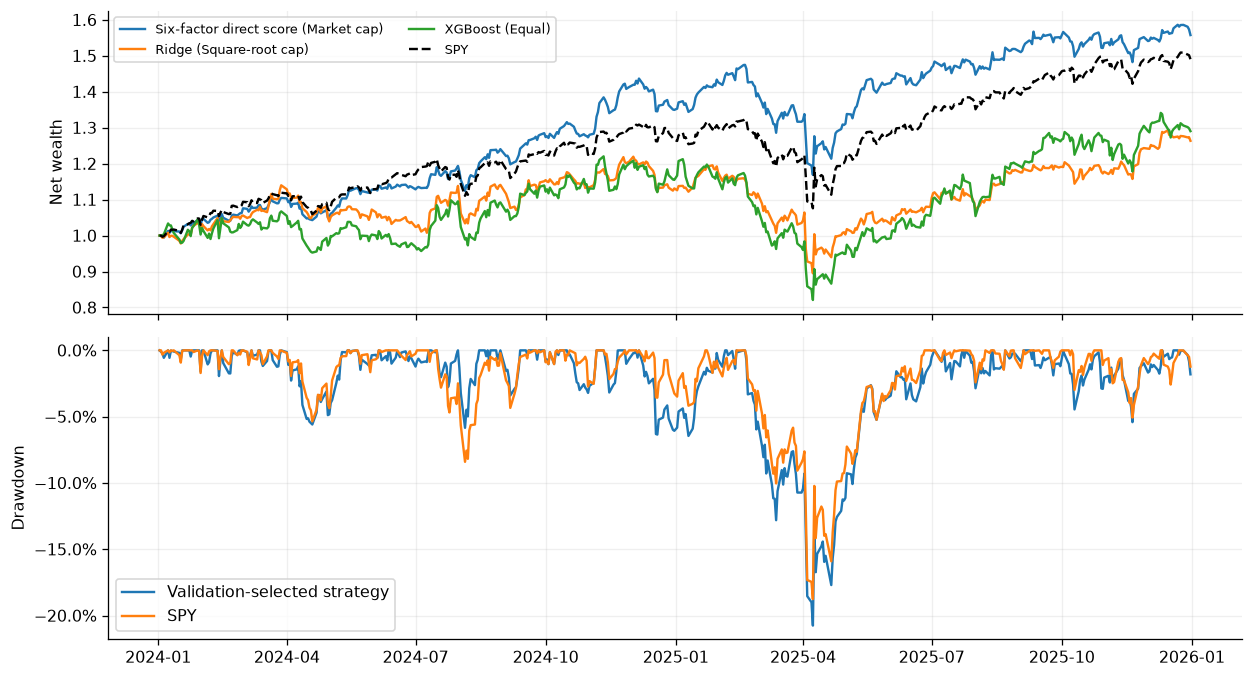

,period,pairs,model_sse,benchmark_sse,oos_r2,model,phase
0,2023 (Validation),511971,4099.019121,4098.845886,-4.226419e-05,fundamental,validation
1,2023 (Validation),511971,4099.013451,4098.845886,-4.088085e-05,ridge,validation
2,2023 (Validation),511971,4098.845886,4098.845886,4.412026e-11,lasso,validation
3,2023 (Validation),511971,4124.745289,4098.845886,-6.318706e-03,xgboost,validation
4,2024,535091,4520.094373,4519.991057,-2.285769e-05,fundamental,evaluation
5,2025,497371,5104.729461,5104.503539,-4.425931e-05,fundamental,evaluation
6,2024-2025,1032462,9624.823834,9624.494596,-3.420838e-05,fundamental,evaluation
7,2024,535091,4520.073157,4519.991057,-1.816382e-05,ridge,evaluation
8,2025,497371,5105.155156,5104.503539,-1.276552e-04,ridge,evaluation
9,2024-2025,1032462,9625.228313,9624.494596,-7.623433e-05,ridge,evaluation


,period,case,sessions,annual_return,annual_volatility,max_drawdown,sharpe
0,2023 (Validation),fundamental_cap,250,0.196123,0.141975,-0.116859,1.332513
1,2023 (Validation),ml_ridge,250,0.165817,0.165938,-0.111463,1.007384
2,2023 (Validation),ml_xgboost_equal,250,0.250439,0.222232,-0.202521,1.116711
3,2023 (Validation),SPY,250,0.259691,0.130482,-0.099743,1.835077
4,2024,fundamental_cap,252,0.349564,0.134198,-0.063491,2.302103
5,2024,ml_ridge,252,0.131237,0.170934,-0.115910,0.806731
6,2024,ml_xgboost_equal,252,0.154995,0.233351,-0.114168,0.733706
7,2024,SPY,252,0.266235,0.125194,-0.084056,1.948813
8,2025,fundamental_cap,250,0.155551,0.196680,-0.207555,0.832565
9,2025,ml_ridge,250,0.118032,0.240165,-0.251414,0.583538


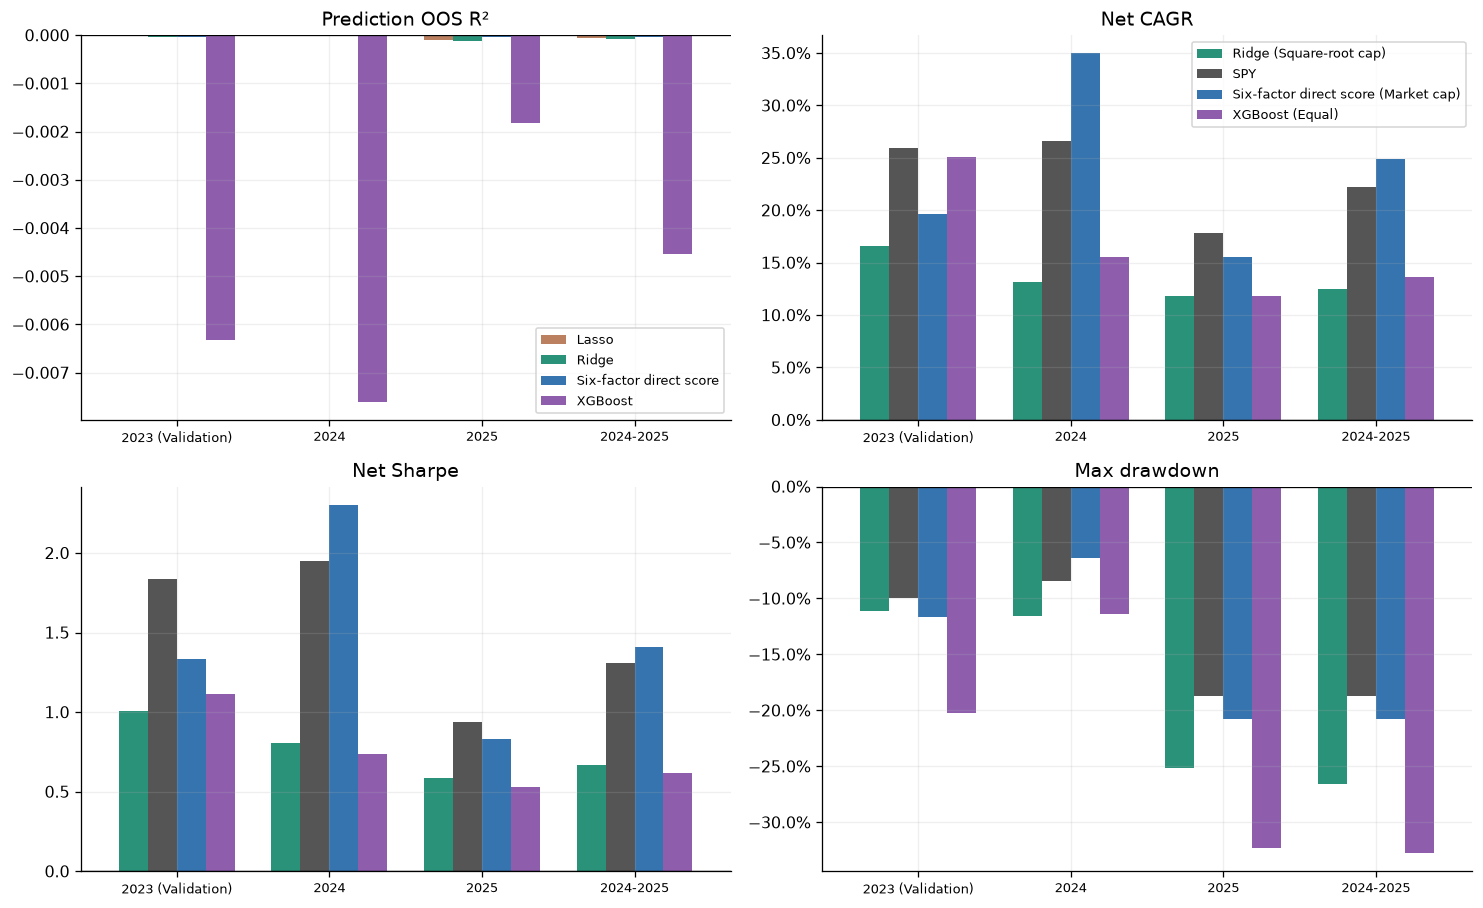

In [8]:
# Evaluate all frozen specifications under identical execution rules.
study.replay_phase('evaluation')
learners.forecast('evaluation')
display(pd.read_csv(learners.out/'evaluation_forecast_diagnostics.csv'))
def daily(case,phase='evaluation'):
    return pd.read_csv(study.out/'portfolios'/case/phase/'daily.csv',dtype={'date':str}).set_index('date')
summary=pd.read_csv(study.out/'portfolio_summary.csv');ev=summary.query("phase=='evaluation'").set_index('case')
show_portfolio_tables(ev.reset_index())
ref=daily(selection['selected_case']);dates=pd.to_datetime(ref.index)
fig,axes=plt.subplots(2,1,figsize=(11,6),sharex=True)
for model, case in frozen_cases.items():
    axes[0].plot(dates, daily(case).net_nav, label=f'{model_names[model]} ({case_labels[case][1]})')
spy=(1+ref.benchmark_return).cumprod();axes[0].plot(dates,spy,'k--',label='SPY');axes[0].legend(ncol=2,fontsize=8);axes[0].set_ylabel('Net wealth')
for nav,name in [(ref.net_nav,'Validation-selected strategy'),(spy,'SPY')]:axes[1].plot(dates,nav/np.maximum(1,nav.cummax())-1,label=name)
axes[1].yaxis.set_major_formatter(PercentFormatter(1));axes[1].set_ylabel('Drawdown');axes[1].legend();fig.tight_layout();plt.show()
# Map the direct rank score to return units using past data only.
learners.fundamental_prediction_r2()
# Align forecast and portfolio metrics to the same period labels.
period_order = ['2023 (Validation)', '2024', '2025', '2024-2025']
r2 = pd.concat([
    pd.read_csv(learners.out / f'{phase}_{model}_oos_r2.csv')
      .pipe(lambda rows: rows.loc[rows.period.eq('Full period')] if phase == 'validation' else rows)
      .assign(model=model, phase=phase)
    for phase in ('validation', 'evaluation') for model in ('fundamental', 'ridge', 'lasso', 'xgboost')
], ignore_index=True)
r2.loc[r2.phase.eq('validation'), 'period'] = period_order[0]
r2['period'] = r2.period.replace('Full period', period_order[-1])
display(r2)

period_rows = []
portfolio_labels = {
    case: f'{model_names[model]} ({case_labels[case][1]})'
    for model, case in frozen_cases.items()
}
portfolio_labels['SPY'] = 'SPY'
for phase in ('validation', 'evaluation'):
    aligned = pd.DataFrame({case: daily(case, phase).net_return for case in frozen_cases.values()})
    aligned['SPY'] = daily(selection['selected_case'], phase).benchmark_return
    assert aligned.notna().all().all()
    periods = [(period_order[0], aligned)] if phase == 'validation' else [
        *aligned.groupby(aligned.index.str[:4]), (period_order[-1], aligned)
    ]
    for period, returns in periods:
        for case, series in returns.items():
            volatility = series.std(ddof=1)
            wealth = (1 + series).cumprod()
            drawdown = wealth / wealth.cummax().clip(lower=1) - 1
            period_rows.append({
                'period': period, 'case': case, 'sessions': len(series),
                'annual_return': (1 + series).prod()**(252 / len(series)) - 1,
                'annual_volatility': volatility * np.sqrt(252),
                'max_drawdown': drawdown.min(),
                'sharpe': series.mean() / volatility * np.sqrt(252) if volatility > 0 else np.nan,
            })
period_metrics = pd.DataFrame(period_rows)
display(period_metrics)

palette = {'fundamental': '#3574af', 'ridge': '#2b927a', 'lasso': '#ba8060',
           'xgboost': '#8e5ead', 'SPY': '#555555'}
score_colors = {model_names[model]: palette[model] for model in model_names}
portfolio_colors = {portfolio_labels[case]: palette[model] for model, case in frozen_cases.items()}
portfolio_colors['SPY'] = palette['SPY']
prediction_view = r2.assign(label=r2.model.map(model_names)).pivot(
    index='period', columns='label', values='oos_r2').reindex(period_order)
portfolio_view = period_metrics.assign(label=period_metrics.case.map(portfolio_labels))
fig, grid = plt.subplots(2, 2, figsize=(13, 8))
axes = grid.ravel()
prediction_view.plot.bar(ax=axes[0], color=score_colors, width=.76)
axes[0].set_title('Prediction OOS R²')
for metric, title, ax in zip(
    ('annual_return', 'sharpe', 'max_drawdown'),
    ('Net CAGR', 'Net Sharpe', 'Max drawdown'),
    axes[1:],
):
    values = portfolio_view.pivot(index='period', columns='label', values=metric).reindex(period_order)
    values.plot.bar(ax=ax, color=portfolio_colors, width=.76)
    ax.set_title(title)
for ax in axes:
    ax.axhline(0, color='black', linewidth=.8)
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=0, labelsize=8)
    ax.legend(fontsize=8)
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
axes[3].yaxis.set_major_formatter(PercentFormatter(1))
axes[2].get_legend().remove()
axes[3].get_legend().remove()
fig.tight_layout()
plt.show()


## 8. Robustness: Costs and Factor Ablation
 Rerun the full ledger at 20/30bps and remove one fundamental factor at a time, re-averaging the remaining five. Keep the sample, allocation, retention rule and rebalance schedule fixed. These are sensitivity checks, not a search for an evaluation-period winner.

The cost and ablation analyses below concern the six-factor square-root-capitalization reference portfolio.

{"stage": "final_portfolio", "case": "cost_20", "phase": "evaluation", "CAGR": 0.2521516301399931}


{"stage": "final_portfolio", "case": "cost_30", "phase": "evaluation", "CAGR": 0.24637202546675563}


{"stage": "final_portfolio", "case": "without_F01", "phase": "evaluation", "CAGR": 0.20625589513208142}


{"stage": "final_portfolio", "case": "without_F02", "phase": "evaluation", "CAGR": 0.21278219836190582}


{"stage": "final_portfolio", "case": "without_F03", "phase": "evaluation", "CAGR": 0.2061171429598061}


{"stage": "final_portfolio", "case": "without_F04", "phase": "evaluation", "CAGR": 0.2515267955289706}


{"stage": "final_portfolio", "case": "without_F05", "phase": "evaluation", "CAGR": 0.21652801528223198}


{"stage": "final_portfolio", "case": "without_F06", "phase": "evaluation", "CAGR": 0.20971741890129758}


,annual_return,gross_cagr,sharpe,max_drawdown,mean_daily_turnover
case,,,,,
fundamental_sqrt_cap,0.257958,0.263793,1.433564,-0.207846,0.009179
cost_20,0.252152,0.263793,1.406060,-0.208317,0.009176
cost_30,0.246372,0.263793,1.378489,-0.208788,0.009174
without_F01,0.206256,0.210614,1.199921,-0.201380,0.007154
without_F02,0.212782,0.220582,1.202582,-0.187926,0.012716
without_F03,0.206117,0.212722,1.114119,-0.217823,0.010833
without_F04,0.251527,0.258675,1.247604,-0.198540,0.011297
without_F05,0.216528,0.222227,1.195484,-0.216246,0.009271
without_F06,0.209717,0.213190,1.246945,-0.171470,0.005686


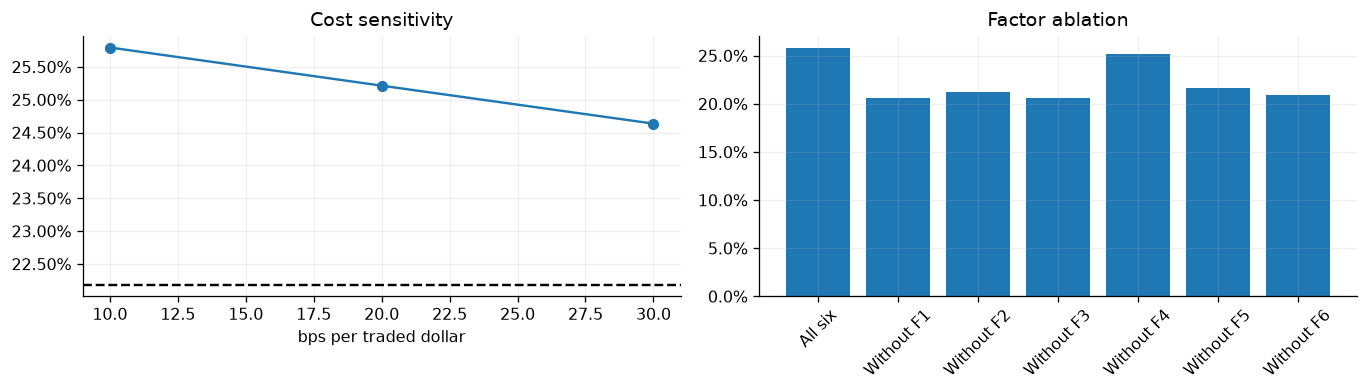

In [9]:
# Change one assumption at a time, keeping portfolio rules fixed.
study.robustness()
summary=pd.read_csv(study.out/'portfolio_summary.csv');ev=summary.query("phase=='evaluation'").set_index('case')
cases=['fundamental_sqrt_cap','cost_20','cost_30']+[f'without_F0{i}' for i in range(1,7)]
display(ev.loc[cases,['annual_return','gross_cagr','sharpe','max_drawdown','mean_daily_turnover']])
fig,axes=plt.subplots(1,2,figsize=(12,3.5))
axes[0].plot([10,20,30],[ev.loc[k,'annual_return'] for k in cases[:3]],marker='o');axes[0].axhline(ev.loc['fundamental_sqrt_cap','spy_annual_return'],color='black',ls='--');axes[0].set(title='Cost sensitivity',xlabel='bps per traded dollar')
axes[1].bar(['All six']+[f'Without F{i}' for i in range(1,7)],[ev.loc[k,'annual_return'] for k in ['fundamental_sqrt_cap']+cases[3:]]);axes[1].tick_params(axis='x',rotation=45);axes[1].set_title('Factor ablation')
for ax in axes:ax.yaxis.set_major_formatter(PercentFormatter(1))
fig.tight_layout();plt.show()

## 9. Return Attribution and Annual Stability
 Decompose the CAGR gap along the square-root-weighted six-factor reference → same-pool square-root allocation → same-pool capitalization allocation → SPY. The adjacent differences telescope exactly, but depend on the selected comparison path. The selection link also includes concentration, target-cap and retention differences; it is not a causal estimate of pure signal alpha.

 Annual attribution uses yearly total-return differences, not three-year CAGR differences. Portfolio allocation and strong performance in an individual year must be distinguished from persistent independent predictability.

This attribution decomposes the six-factor square-root-capitalization reference portfolio relative to SPY.

,phase,link,upper,lower,cagr_difference,ci_low,ci_high,active_mean_annualized,tracking_error,information_ratio,detectable_excess
0,validation,selection,fundamental_sqrt_cap,pool_sqrt_cap,0.010230,-0.140840,0.121436,0.006529,0.053555,0.121918,0.107538
1,validation,weighting,pool_sqrt_cap,pool_cap,-0.071596,-0.174201,0.077232,-0.055674,0.053825,-1.034348,0.108080
2,validation,universe,pool_cap,SPY,-0.002099,-0.037313,0.044627,-0.000988,0.015556,-0.063536,0.031237
3,validation,total,fundamental_sqrt_cap,SPY,-0.063464,-0.166348,0.070407,-0.050133,0.055485,-0.903537,0.111414
4,evaluation,selection,fundamental_sqrt_cap,pool_sqrt_cap,0.108015,0.012625,0.216439,0.090188,0.049787,1.811493,0.070549
5,evaluation,weighting,pool_sqrt_cap,pool_cap,-0.062064,-0.143732,0.023661,-0.051896,0.057669,-0.899888,0.081719
6,evaluation,universe,pool_cap,SPY,-0.009865,-0.031114,0.014272,-0.008013,0.017046,-0.470092,0.024155
7,evaluation,total,fundamental_sqrt_cap,SPY,0.036086,-0.083901,0.178983,0.030279,0.080203,0.377533,0.113649


,phase,weighting,link,upper,lower,cagr_difference,ci_low,ci_high,active_mean_annualized,tracking_error,information_ratio,detectable_excess
0,validation,equal,selection,fundamental_equal,pool_equal,-0.007317,-0.218667,0.119156,-0.011479,0.067316,-0.170532,0.135169
1,validation,sqrt_cap,selection,fundamental_sqrt_cap,pool_sqrt_cap,0.010230,-0.140840,0.121436,0.006529,0.053555,0.121918,0.107538
2,validation,cap,selection,fundamental_cap,pool_cap,-0.061470,-0.166866,0.063633,-0.049273,0.049287,-0.999704,0.098968
3,evaluation,equal,selection,fundamental_equal,pool_equal,0.130674,0.010617,0.257142,0.108483,0.060277,1.799724,0.085415
4,evaluation,sqrt_cap,selection,fundamental_sqrt_cap,pool_sqrt_cap,0.108015,0.012625,0.216439,0.090188,0.049787,1.811493,0.070549
5,evaluation,cap,selection,fundamental_cap,pool_cap,0.037174,-0.069600,0.158520,0.030941,0.073406,0.421499,0.104018


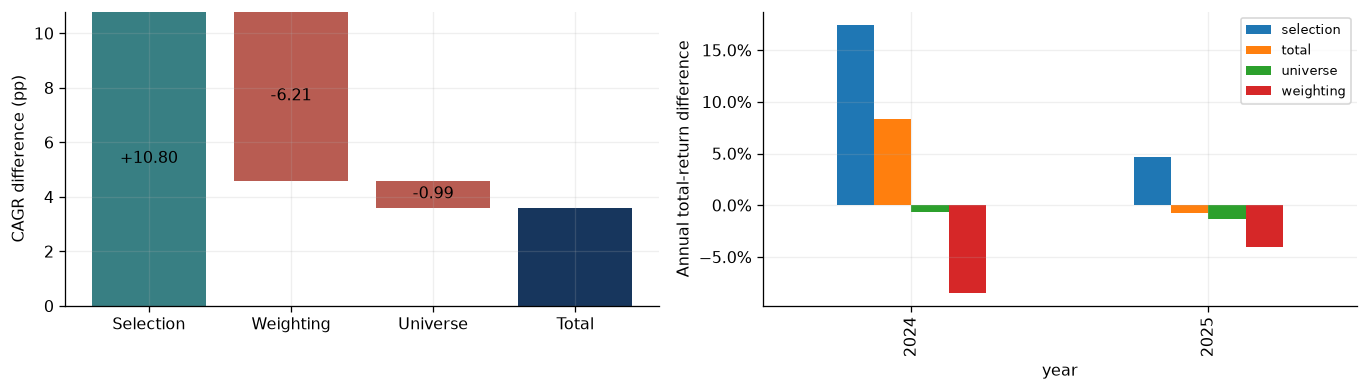

In [10]:
# Decompose matched return differences without refitting the strategy.
from usq.project2.attribution import build
attribution=build(study.out,tables=WORK/'attribution')
z=attribution['attribution'].query("phase=='evaluation'").set_index('link')
display(attribution['attribution']);display(attribution['selection'])
np.testing.assert_allclose(z.loc[['selection','weighting','universe'],'cagr_difference'].sum(),z.loc['total','cagr_difference'],atol=1e-12)
fig,axes=plt.subplots(1,2,figsize=(12,3.5));start=0
for i,key in enumerate(['selection','weighting','universe']):
    v=z.loc[key,'cagr_difference']*100;axes[0].bar(i,v,bottom=start,color='#387f83' if v>=0 else '#b85c52');axes[0].text(i,start+v/2,f'{v:+.2f}',ha='center',va='center');start+=v
axes[0].bar(3,start,color='#17365d');axes[0].set_xticks(range(4),['Selection','Weighting','Universe','Total']);axes[0].set_ylabel('CAGR difference (pp)')
annual=attribution['annual'].query("phase=='evaluation'");annual.pivot(index='year',columns='link',values='return_difference').plot.bar(ax=axes[1]);axes[1].yaxis.set_major_formatter(PercentFormatter(1));axes[1].set_ylabel('Annual total-return difference');axes[1].legend(fontsize=8);fig.tight_layout();plt.show()

## 10. Holdings-Based Risk Factor Attribution

The project uses a US adaptation of the repository’s CNE5-style research model, estimated on the supplied equity universe. Each day, a joint weighted cross-sectional regression explains stock returns using market, SIC industry and standardized style exposures at the previous close. Regression weights are proportional to the square root of capitalization, and industry factor returns are constrained to have zero capitalization-weighted sum. Missing descriptors are reported below. [MSCI methodology reference](https://www.msci.com/documents/10199/ed6e42a3-c1fa-4430-89ba-efd5a5b52558)

For the validation-selected strategy, portfolio exposure is the beginning-of-day holding-weighted sum of stock exposures. Exposure times factor return gives the daily contribution. The market exposure measures invested weight, while the Beta style measures relative stock beta in standardized units. The ledger's gross return less systematic contributions is specific or unexplained return. Trading costs enter separately. Carino linking makes the components add to the cumulative net return.

Residual alpha is 252 times the mean daily return left after subtracting systematic contributions and costs. We report a 95% interval using 10-lag Newey–West standard errors. This is conditional on the estimated risk model and includes effects the model does not capture, including residual industry coverage, stale marks and settlement assumptions. SPY remains a performance benchmark. The exposures below are the strategy's holdings exposures.


/Users/jiarui/Documents/Codex/2026-11-02/python-data-dta-csho-ceq-ni/work/team34_main_validation_20261111/src/usq/barra/exposures.py:95: UserWarning: Growth: 没有可用细项，跳过
  factors = style_exposures(desc, cap.loc[dates], universe.loc[dates])


**2024–2025 factor attribution · fundamental_cap**

,linked_contribution
component,
Market,+48.76%
Industry,+0.36%
Style,-13.00%
Specific / unexplained,+20.81%
Trading costs,-1.16%


,sessions,HAC_lags,annualized_alpha,annualized_HAC_se,HAC_t,p_value_two_sided,ci95_lower,ci95_upper
0,502,10,+7.92%,2.95%,2.68,0.007,+2.13%,+13.71%


**Style exposures and linked contributions**

,mean_exposure,linked_contribution
factor,,
Size,-1.450,-9.44%
Beta,-0.172,-2.34%
Momentum,-0.088,-1.39%
ResidualVolatility,-0.020,-0.34%
NonLinearSize,+0.585,-0.87%
BookToPrice,-0.386,-0.84%
Liquidity,+0.111,+0.43%
EarningsYield,+0.224,+0.22%
Leverage,+0.985,+1.57%


**Eight largest industry exposures by average portfolio weight**

,mean_exposure,linked_contribution
factor,,
Industry:SIC2:73,24.34%,-2.86%
Industry:SIC2:28,9.74%,+0.69%
Industry:SIC2:67,7.66%,-0.61%
Industry:SIC2:35,5.28%,+0.40%
Industry:SIC2:38,4.42%,-0.09%
Industry:SIC2:36,4.11%,+0.88%
Industry:SIC2:87,3.96%,-0.77%
Industry:SIC2:21,3.96%,+1.91%


Mean held weight with missing style                     0.000006
Mean held weight with unavailable industry return       0.000000
Median daily cross-sectional R²                         0.232015
Median daily regression stock count                  2130.000000
dtype: float64

Missing style factors: Growth
Missing descriptors: BLEV, EGRLF, EGRO, EGRSF, EPFWD, MLEV, SGRO


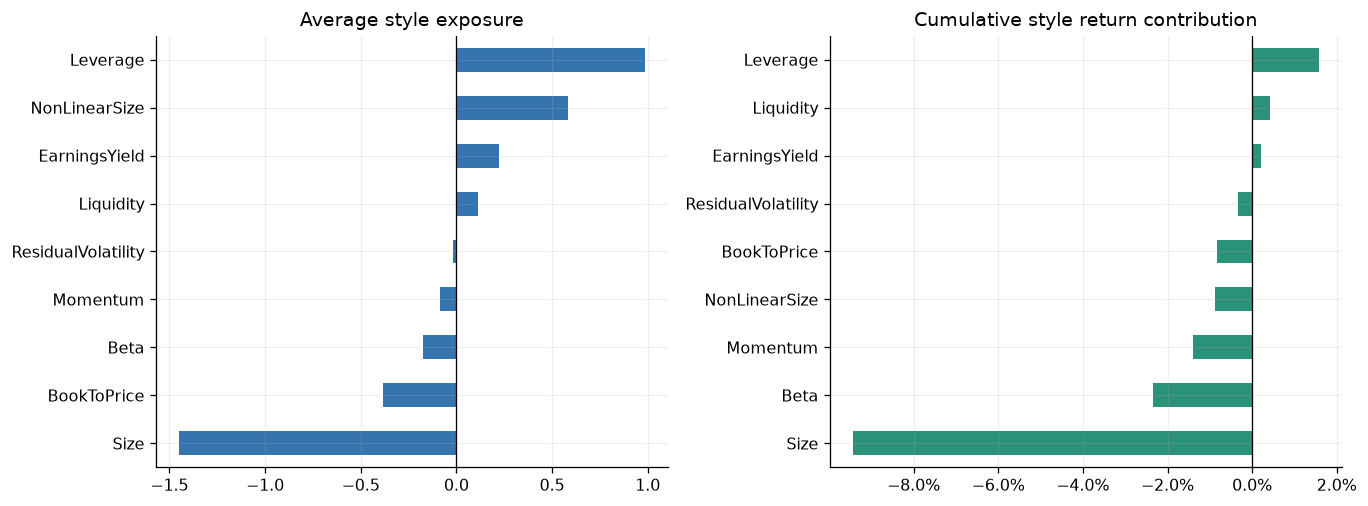

In [11]:
from usq.project2.selected_risk_attribution import build_selected_attribution

risk_case = selection['selected_case']
risk_dir = WORK / 'risk_attribution'
risk_portfolio = study.out / 'portfolios' / risk_case / 'evaluation'
components, factor_table, alpha, coverage, risk_meta = build_selected_attribution(
    database, risk_portfolio, risk_dir
)

display(Markdown(f'**2024–2025 factor attribution · {risk_case}**'))
display(components.style.format('{:+.2%}'))
display(alpha.style.format({
    'annualized_alpha': '{:+.2%}', 'annualized_HAC_se': '{:.2%}', 'HAC_t': '{:.2f}',
    'p_value_two_sided': '{:.3f}', 'ci95_lower': '{:+.2%}', 'ci95_upper': '{:+.2%}',
}))
style_table = factor_table.loc[risk_meta['styles']]
display(Markdown('**Style exposures and linked contributions**'))
display(style_table.style.format({'mean_exposure': '{:+.3f}', 'linked_contribution': '{:+.2%}'}))
industry_table = factor_table.loc[factor_table.index.str.startswith('Industry:')]
display(Markdown('**Eight largest industry exposures by average portfolio weight**'))
display(industry_table.nlargest(8, 'mean_exposure').style.format({
    'mean_exposure': '{:.2%}', 'linked_contribution': '{:+.2%}',
}))
display(pd.Series({
    'Mean held weight with missing style': coverage.missing_style_weight.mean(),
    'Mean held weight with unavailable industry return': coverage.missing_industry_factor_weight.mean(),
    'Median daily cross-sectional R²': coverage.cross_section_r2.median(),
    'Median daily regression stock count': coverage.n_obs.median(),
}))
print('Missing style factors:', ', '.join(risk_meta['missing_styles']))
print('Missing descriptors:', ', '.join(risk_meta['missing_descriptors']))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
style_table.mean_exposure.sort_values().plot.barh(ax=axes[0], color='#3574af')
style_table.linked_contribution.sort_values().plot.barh(ax=axes[1], color='#2b927a')
axes[0].set_title('Average style exposure')
axes[1].set_title('Cumulative style return contribution')
axes[1].xaxis.set_major_formatter(PercentFormatter(1))
for ax in axes:
    ax.axvline(0, color='black', linewidth=.8)
    ax.set_ylabel('')
fig.tight_layout()
plt.show()


## 11. Market Exposure and Statistical Uncertainty
 A supplementary market model regresses daily strategy returns on SPY with an intercept, zero cash interest, and ten-lag Newey–West errors. Its intercept is not treated as confirmed alpha.

 Paired circular block bootstrap uses common sessions, seed 5205 and 2,000 resamples. The 20-session block intervals below describe the observed return paths conditional on research choices; they do not correct for every specification search. The diagnostic `2 × tracking error / sqrt(years)` is only an approximate arithmetic-active-return scale, not formal CAGR power analysis.

,phase,case,cagr,alpha_annualized,beta,alpha_t_hac,residual_volatility,correlation,active_mean_annualized,tracking_error,information_ratio,detectable_excess
0,validation,fundamental_sqrt_cap,0.196227,-0.051069,1.003910,-1.015713,0.055595,0.920808,-0.050133,0.055485,-0.903537,0.111414
1,validation,fundamental_cap,0.196123,-0.050805,1.002272,-0.986319,0.055373,0.921139,-0.050261,0.055262,-0.909509,0.110965
2,validation,fundamental_equal,0.159680,-0.090905,1.049746,-1.272093,0.076774,0.872738,-0.078994,0.076894,-1.027311,0.154402
3,validation,pool_sqrt_cap,0.185997,-0.077303,1.086202,-1.237938,0.065841,0.907240,-0.056662,0.066664,-0.849965,0.133861
4,validation,pool_cap,0.257593,-0.008898,1.033033,-0.643113,0.014978,0.993908,-0.000988,0.015556,-0.063536,0.031237
5,evaluation,fundamental_sqrt_cap,0.257958,0.047051,0.921521,0.851472,0.079249,0.885220,0.030279,0.080203,0.377533,0.113649
6,evaluation,fundamental_cap,0.249182,0.042232,0.909664,0.785759,0.078508,0.884538,0.022927,0.079808,0.287279,0.113090
7,evaluation,fundamental_equal,0.247186,0.030434,0.972733,0.445268,0.097915,0.851776,0.024607,0.097918,0.251300,0.138753
8,evaluation,pool_sqrt_cap,0.149944,-0.047645,0.942613,-1.042847,0.066954,0.917323,-0.059909,0.067542,-0.886989,0.095709
9,evaluation,pool_cap,0.212008,-0.007347,0.996879,-0.687150,0.017056,0.994580,-0.008013,0.017046,-0.470092,0.024155


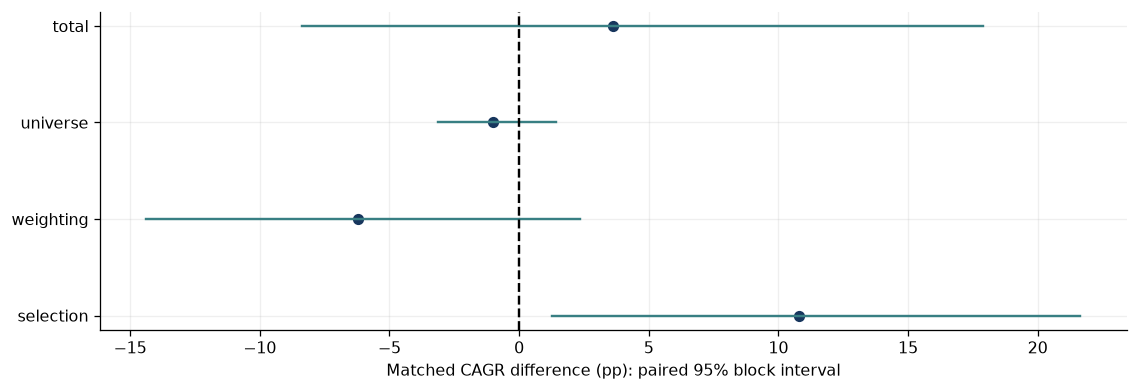

In [12]:
# Report dependence-aware uncertainty alongside point estimates.
display(attribution['capm'])
ci=attribution['attribution'].query("phase=='evaluation'")
fig,ax=plt.subplots(figsize=(10,3.5))
for i,r in enumerate(ci.itertuples()):ax.plot([r.ci_low*100,r.ci_high*100],[i,i],color='#387f83');ax.scatter(r.cagr_difference*100,i,color='#17365d')
ax.axvline(0,color='black',ls='--');ax.set_yticks(range(len(ci)),ci.link);ax.set_xlabel('Matched CAGR difference (pp): paired 95% block interval');fig.tight_layout();plt.show()

## 12. Accounting Verification and Conclusions
 Require unique sorted dates, finite returns, self-financing cash constraints, fee consistency and exact compounded wealth. Daily gross returns are also checked against actual beginning-of-period holdings and independently constructed asset returns. No archived strategy-return table is used as an input to these portfolio calculations.

 The final interpretation jointly considers return, risk, turnover, benchmark choice and uncertainty. Latest financial vintages, supplied universe lineage and unresolved terminal settlements limit economic claims, even when the numerical audit passes.

In [13]:
# Reconcile portfolio accounting before interpreting performance.
checks=study.audit();display(pd.DataFrame(checks['checks']));print('Maximum holdings reconciliation error:',checks['maximum_independent_holdings_error'])
choice=json.loads((learners.out/'frozen_family.json').read_text())['selected_case']
r=ev.loc[choice]
display(pd.read_csv(learners.out/'training_history.csv'))
display(Markdown(f"The validation-selected strategy **{choice}** earns **{r.annual_return:.2%}** net CAGR, Sharpe **{r.sharpe:.3f}**, and maximum drawdown **{r.max_drawdown:.2%}** in evaluation. Aligned SPY CAGR is **{r.spy_annual_return:.2%}**. Point estimates, stress tests and intervals must be interpreted together; this exploratory exercise does not establish robust benchmark outperformance."))
comparison=ev.loc[list(frozen_cases.values()),['annual_return','annual_volatility','sharpe','max_drawdown','mean_daily_turnover']]
display(comparison)
print('CV parameters and the selected family were frozen before evaluation fitting; all twelve evaluation candidates are retained.')
# Save presentation outputs from this experiment only.
import shutil
RESULTS=ROOT/'results'
RESULTS.mkdir(exist_ok=True)
for name in ['portfolio_summary.csv','factor_statistics.csv','portfolio_audit.json']:
    shutil.copy2(study.out/name,RESULTS/name)
for name in ['CV_scores.csv','CV_comparison.csv','feature_manifest.csv','frozen_hyperparameters.json','frozen_family.json','training_history.csv']:
    shutil.copy2(learners.out/name,RESULTS/name)

for name in ['WQ_screen.csv','WQ_annual.csv','WQ_selection.json']:
    shutil.copy2(WORK/'factor_screen'/name,RESULTS/name)

r2.loc[r2.phase.eq('evaluation')].to_csv(RESULTS / 'evaluation_oos_r2.csv', index=False)
r2.to_csv(RESULTS / 'period_oos_r2.csv', index=False)
period_metrics.to_csv(RESULTS / 'period_metrics.csv', index=False)

for name in ('components', 'factors', 'alpha', 'coverage'):
    shutil.copy2(risk_dir / f'{name}.csv', RESULTS / f'barra_{name}.csv')


,case,phase,sessions,accounting_passed
0,pool_equal,validation,250,True
1,fundamental_equal,validation,250,True
2,pool_sqrt_cap,validation,250,True
3,fundamental_sqrt_cap,validation,250,True
4,pool_cap,validation,250,True
5,fundamental_cap,validation,250,True
6,ml_ridge_equal,validation,250,True
7,ml_ridge,validation,250,True
8,ml_ridge_cap,validation,250,True
9,ml_lasso_equal,validation,250,True


Maximum holdings reconciliation error: 1.2854668603873298e-08


,model,half,params,samples,training_target_mean,features,feature_set,fit_converged,solver_iterations,solver_dual_gap,...,train_first,train_last_signal,train_last_label_end,forecast_start,forecast_end,seconds,nonzero_value_coefficients,nonzero_missing_coefficients,tag,reused_verified_fit
0,ridge,2020H1,"{""alpha_per_sample"": 1.0, ""feature_set"": ""fund...",2521845,0.004609,12,fundamental,True,NaN,NaN,...,20150114,20191213,20191231,20200101,20200630,0.674242,6.0,6.0,cv_grid0,False
1,ridge,2020H2,"{""alpha_per_sample"": 1.0, ""feature_set"": ""fund...",2763371,0.003681,12,fundamental,True,NaN,NaN,...,20150114,20200615,20200630,20200701,20201231,0.556578,6.0,6.0,cv_grid0,False
2,ridge,2021H1,"{""alpha_per_sample"": 1.0, ""feature_set"": ""fund...",3023300,0.005553,12,fundamental,True,NaN,NaN,...,20150114,20201215,20201231,20210101,20210630,0.854205,6.0,6.0,cv_grid0,False
3,ridge,2021H2,"{""alpha_per_sample"": 1.0, ""feature_set"": ""fund...",3294934,0.006472,12,fundamental,True,NaN,NaN,...,20150114,20210615,20210630,20210701,20211231,0.762687,6.0,6.0,cv_grid0,False
4,ridge,2022H1,"{""alpha_per_sample"": 1.0, ""feature_set"": ""fund...",3579334,0.006010,12,fundamental,True,NaN,NaN,...,20150114,20211215,20211231,20220101,20220630,0.951663,6.0,6.0,cv_grid0,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
391,lasso,2025H2,"{""alpha"": 0.0005, ""feature_set"": ""combined""}",2660868,0.005178,24,combined,True,2.0,-6.836075e-19,...,20200701,20250612,20250630,20250701,20251231,0.818391,1.0,0.0,forecast,False
392,xgboost,2024H1,"{""max_depth"": 4, ""learning_rate"": 0.08, ""reg_l...",2619388,0.005508,24,combined,True,NaN,NaN,...,20190102,20231213,20231229,20240101,20240630,10.777276,NaN,NaN,forecast,False
393,xgboost,2024H2,"{""max_depth"": 4, ""learning_rate"": 0.08, ""reg_l...",2634391,0.004492,24,combined,True,NaN,NaN,...,20190701,20240612,20240628,20240701,20241231,10.762905,NaN,NaN,forecast,False
394,xgboost,2025H1,"{""max_depth"": 4, ""learning_rate"": 0.08, ""reg_l...",2648671,0.004821,24,combined,True,NaN,NaN,...,20200102,20241213,20241231,20250101,20250630,10.536483,NaN,NaN,forecast,False


The validation-selected strategy **fundamental_cap** earns **24.92%** net CAGR, Sharpe **1.407**, and maximum drawdown **-20.76%** in evaluation. Aligned SPY CAGR is **22.19%**. Point estimates, stress tests and intervals must be interpreted together; this exploratory exercise does not establish robust benchmark outperformance.

,annual_return,annual_volatility,sharpe,max_drawdown,mean_daily_turnover
case,,,,,
fundamental_cap,0.249182,0.168134,1.407403,-0.207555,0.009197
ml_ridge,0.124641,0.208099,0.668033,-0.266012,0.063460
ml_xgboost_equal,0.136593,0.262875,0.618038,-0.327393,0.054108


CV parameters and the selected family were frozen before evaluation fitting; all twelve evaluation candidates are retained.
